<a href="https://colab.research.google.com/github/SHRESHTH121/Hugging-Face/blob/main/IP_ASS_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Part 1**

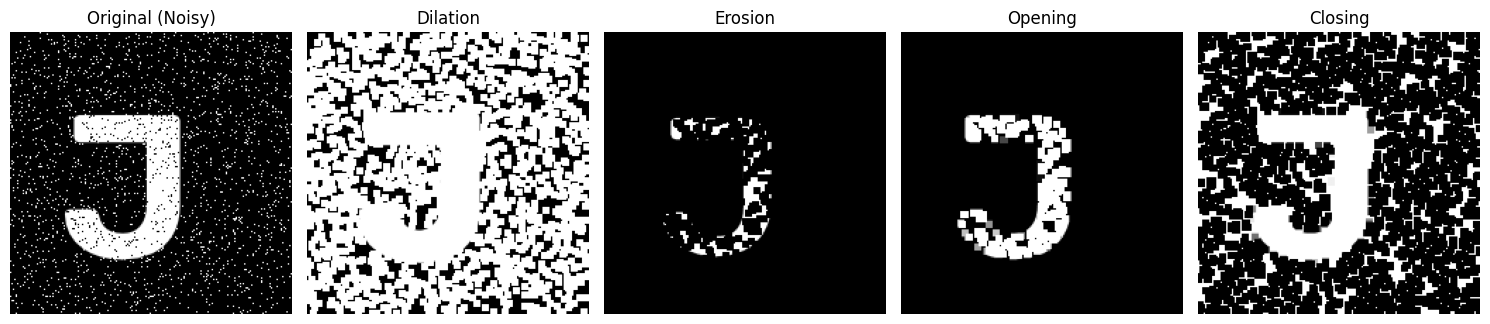

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = np.zeros((200, 200), dtype=np.uint8)
cv2.putText(image, 'J', (35, 160), cv2.FONT_HERSHEY_SIMPLEX, 5, 255, 10)

noise_pepper = np.random.randint(0, 2, size=image.shape, dtype=np.uint8) * 255
noise_pepper_mask = np.random.rand(*image.shape) < 0.05
image_with_noise = image.copy()
image_with_noise[noise_pepper_mask] = 255 - image_with_noise[noise_pepper_mask]

kernel = np.ones((5, 5), np.uint8)

dilation = cv2.dilate(image_with_noise, kernel, iterations=1)
erosion = cv2.erode(image_with_noise, kernel, iterations=1)
opening = cv2.morphologyEx(image_with_noise, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(image_with_noise, cv2.MORPH_CLOSE, kernel)

titles = ['Original (Noisy)', 'Dilation', 'Erosion', 'Opening', 'Closing']
images = [image_with_noise, dilation, erosion, opening, closing]

plt.figure(figsize=(15, 6))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

# **Part 2**

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math

def add_salt_and_pepper_noise(image, salt_prob, pepper_prob):
    noisy_image = image.copy()
    num_salt = np.ceil(salt_prob * image.size)
    coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
    noisy_image[tuple(coords)] = 255

    num_pepper = np.ceil(pepper_prob * image.size)
    coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
    noisy_image[tuple(coords)] = 0
    return noisy_image

def calculate_psnr(img1, img2):
    mse = np.mean((img1 - img2) ** 2)
    if mse == 0:
        return float('inf')
    max_pixel = 255.0
    return 20 * math.log10(max_pixel / math.sqrt(mse))

def adaptive_median_filter(image, s_init, s_max):
    pad_size = s_max // 2
    padded_image = cv2.copyMakeBorder(image, pad_size, pad_size, pad_size, pad_size, cv2.BORDER_REFLECT)
    output_image = np.zeros_like(image)

    rows, cols = image.shape

    for i in range(rows):
        for j in range(cols):
            pi = i + pad_size
            pj = j + pad_size

            w_size = s_init
            while w_size <= s_max:
                half_w = w_size // 2
                window = padded_image[pi - half_w : pi + half_w + 1, pj - half_w : pj + half_w + 1]

                z_min = np.min(window)
                z_max = np.max(window)
                z_med = np.median(window)
                z_xy = padded_image[pi, pj]

                if z_min < z_med < z_max:
                    if z_min < z_xy < z_max:
                        output_image[i, j] = z_xy
                    else:
                        output_image[i, j] = z_med
                    break
                else:
                    w_size += 2
            else:
                output_image[i, j] = z_med

    return output_image

PSNR (Noisy Image): 57.20 dB
PSNR (Standard Median Filter 3x3): 70.51 dB
PSNR (Adaptive Median Filter [3 to 7]): 73.39 dB


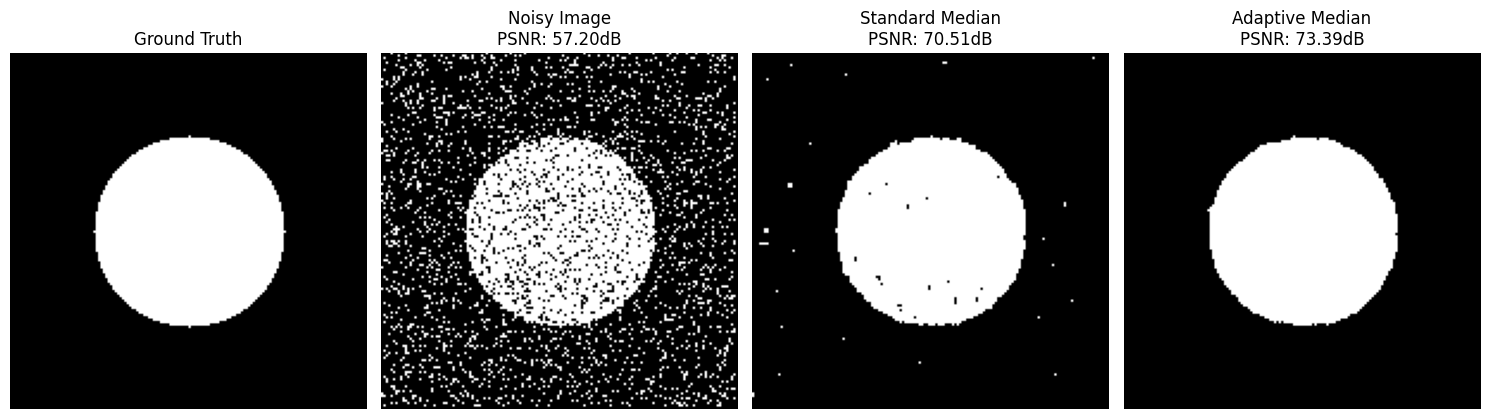

In [3]:
synthetic_base = np.zeros((150, 150), dtype=np.uint8)
cv2.circle(synthetic_base, (75, 75), 40, 255, -1)

noisy_image = add_salt_and_pepper_noise(synthetic_base, 0.15, 0.15)

S_INIT = 3
S_MAX = 7

standard_median = cv2.medianBlur(noisy_image, 3)

adaptive_median = adaptive_median_filter(noisy_image, S_INIT, S_MAX)

psnr_noisy = calculate_psnr(synthetic_base, noisy_image)
psnr_standard = calculate_psnr(synthetic_base, standard_median)
psnr_adaptive = calculate_psnr(synthetic_base, adaptive_median)

print(f"PSNR (Noisy Image): {psnr_noisy:.2f} dB")
print(f"PSNR (Standard Median Filter 3x3): {psnr_standard:.2f} dB")
print(f"PSNR (Adaptive Median Filter [{S_INIT} to {S_MAX}]): {psnr_adaptive:.2f} dB")

plt.figure(figsize=(15, 5))
plt.subplot(1, 4, 1)
plt.imshow(synthetic_base, cmap='gray')
plt.title('Ground Truth')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(noisy_image, cmap='gray')
plt.title(f'Noisy Image\nPSNR: {psnr_noisy:.2f}dB')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(standard_median, cmap='gray')
plt.title(f'Standard Median\nPSNR: {psnr_standard:.2f}dB')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(adaptive_median, cmap='gray')
plt.title(f'Adaptive Median\nPSNR: {psnr_adaptive:.2f}dB')
plt.axis('off')

plt.tight_layout()
plt.show()